<a href="https://colab.research.google.com/github/saikirankesoju/Quantum_Computing/blob/main/Product_1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Installing missing package: qiskit ...
Installing missing package: qiskit-aer ...
Qiskit version: 2.6.2 | AerSimulator available: True

RUNNING 16 AUTOMATED UNIT TESTS: PRODUCT 1
[PASSED ] Test 1: Identity Gate Unitary
[PASSED ] Test 2: Pauli-X Bit-Flip
[PASSED ] Test 3: Pauli-Y Unitary
[PASSED ] Test 4: Pauli-Z Phase Inversion
[PASSED ] Test 5: Hadamard Superposition
[FAILED ] Test 6: Phase-S Gate Unitary
[FAILED ] Test 7: Phase-T Gate Non-Clifford Phase
[PASSED ] Test 8: Rotation Rx Gate
[PASSED ] Test 9: Measurement Register Preservation
[PASSED ] Test 10: CNOT Conditional Flip
[PASSED ] Test 11: Controlled-Z Entanglement
[FAILED ] Test 12: SWAP State Permutation
[PASSED ] Test 13: Toffoli Dual-Condition Activation
[PASSED ] Test 14: Bell State (|00> + |11>) Fidelity
[PASSED ] Test 15: GHZ Tripartite Entanglement
[PASSED ] Test 16: Transpilation Depth Monotonicity
----------------------------------------------------------------------
OVERALL RESULT: FAILED

Simulating all 15 Quantum

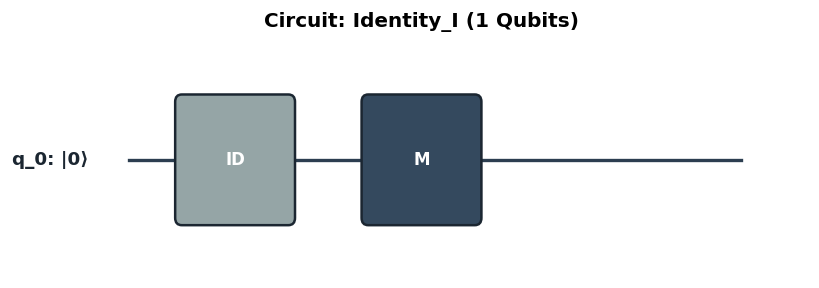

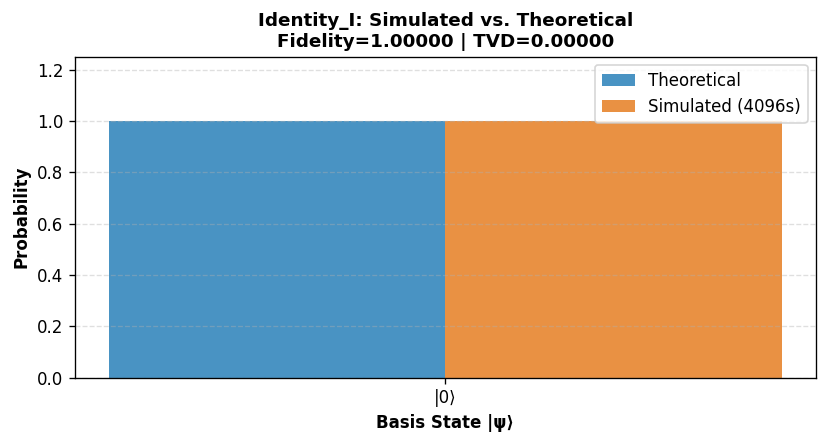

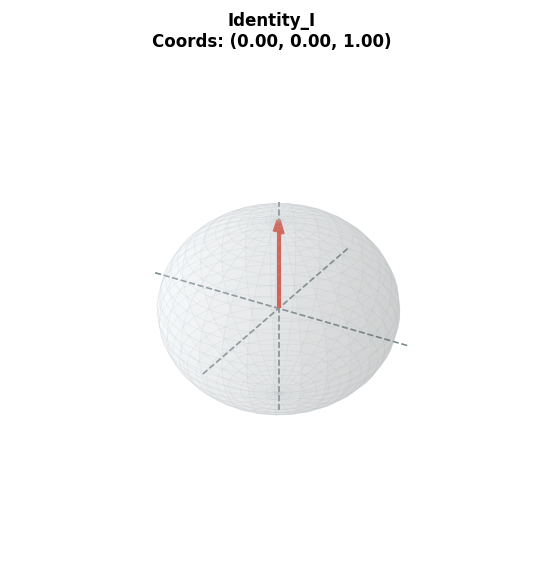


CIRCUIT 2: PAULI-X (NOT) CIRCUIT
Qubits: 1 | Shots: 4096 | Fidelity: 1.00000 | TVD: 0.00000
Counts: {'1': 4096}


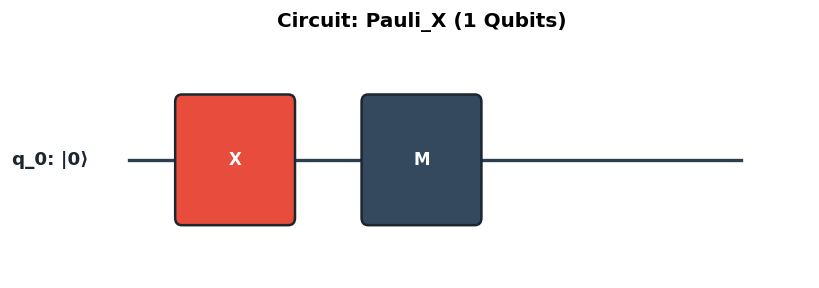

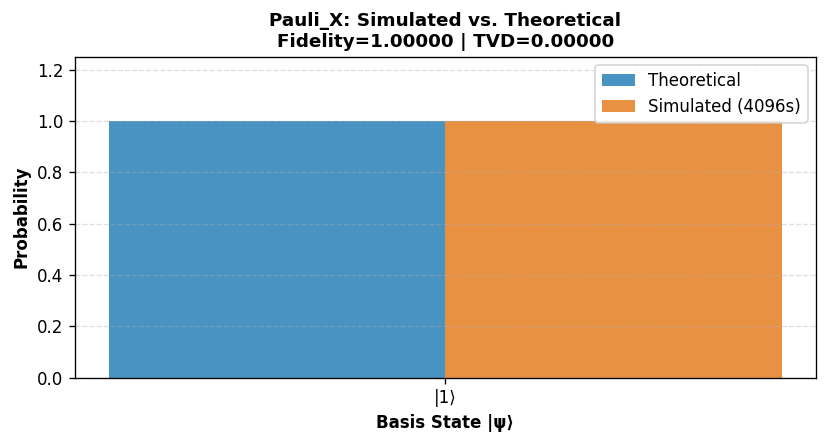

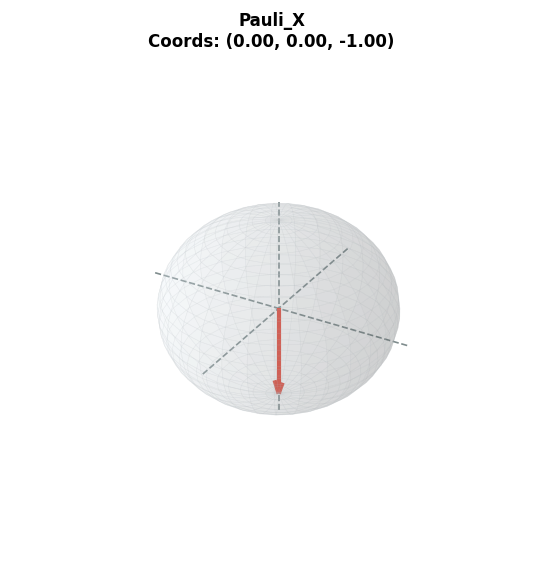


CIRCUIT 3: PAULI-Y CIRCUIT
Qubits: 1 | Shots: 4096 | Fidelity: 1.00000 | TVD: 0.00000
Counts: {'1': 4096}


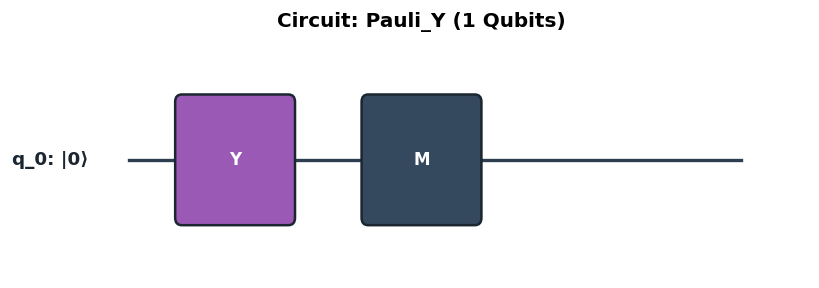

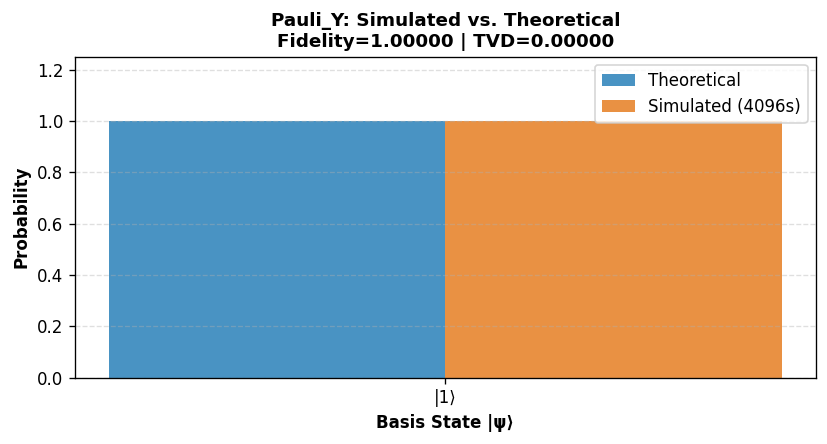

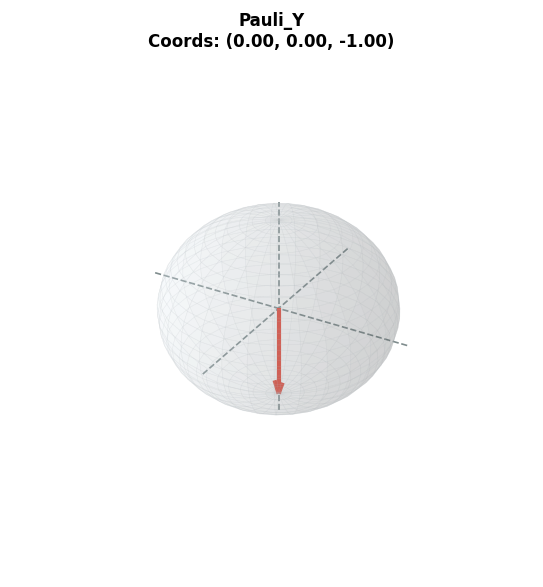


CIRCUIT 4: PAULI-Z (PHASE-FLIP) CIRCUIT
Qubits: 1 | Shots: 4096 | Fidelity: 1.00000 | TVD: 0.00000
Counts: {'1': 4096}


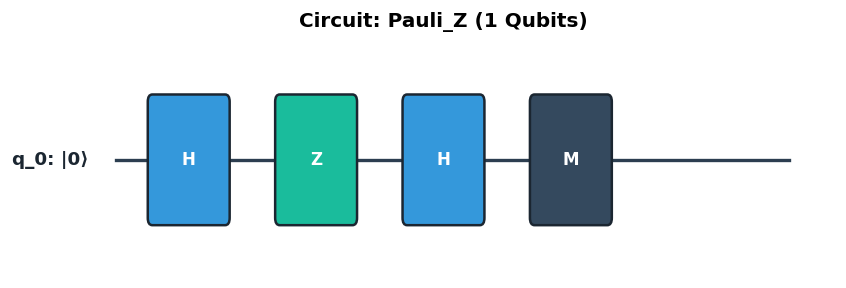

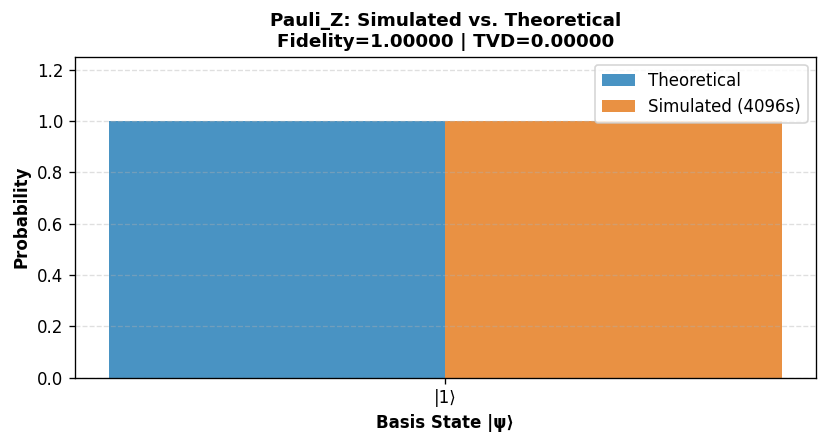

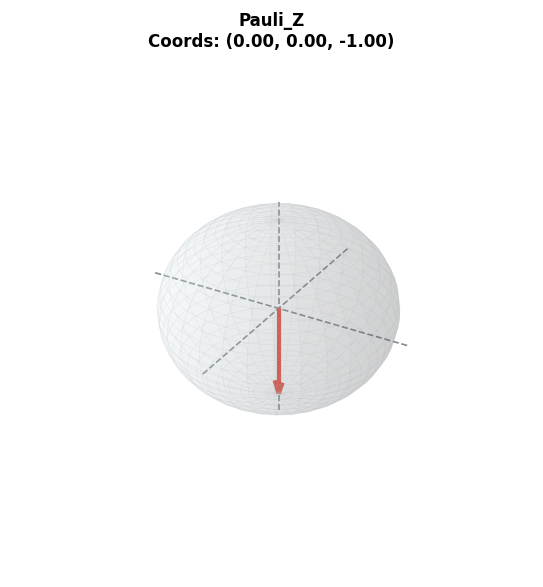


CIRCUIT 5: HADAMARD (H) CIRCUIT
Qubits: 1 | Shots: 4096 | Fidelity: 0.99996 | TVD: 0.00635
Counts: {'0': 2022, '1': 2074}


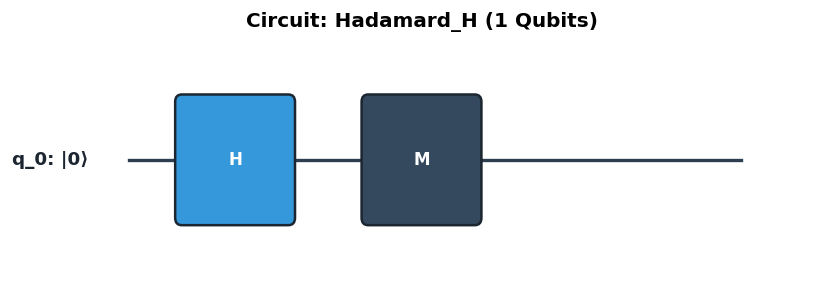

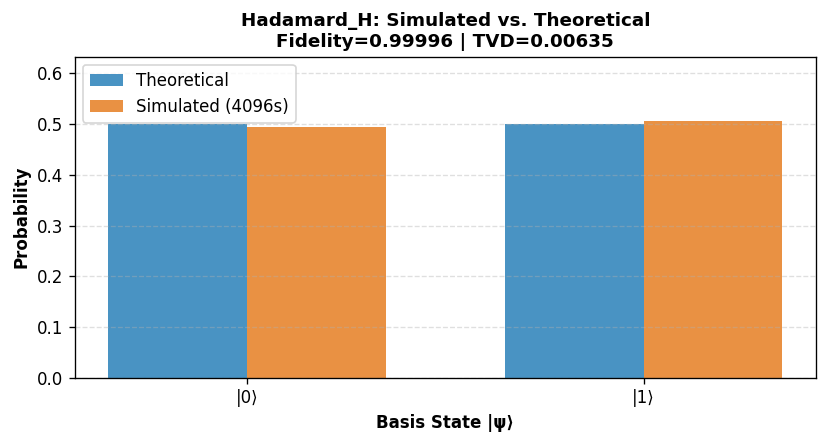

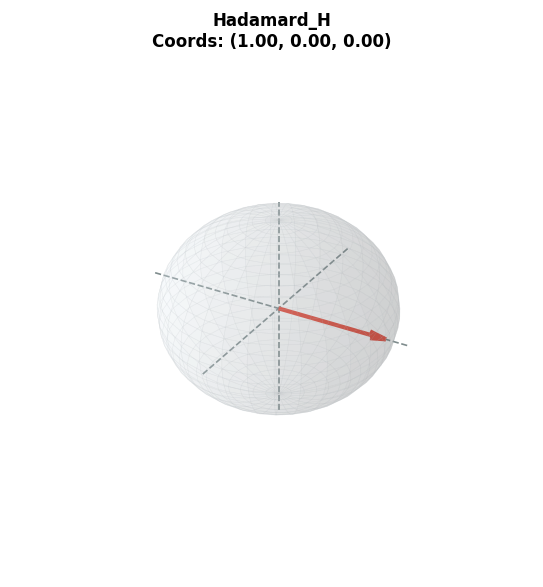


CIRCUIT 6: PHASE-S CIRCUIT
Qubits: 1 | Shots: 4096 | Fidelity: 0.99996 | TVD: 0.00635
Counts: {'0': 2022, '1': 2074}


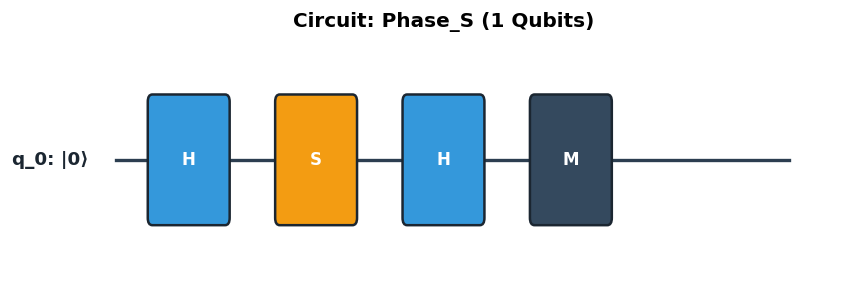

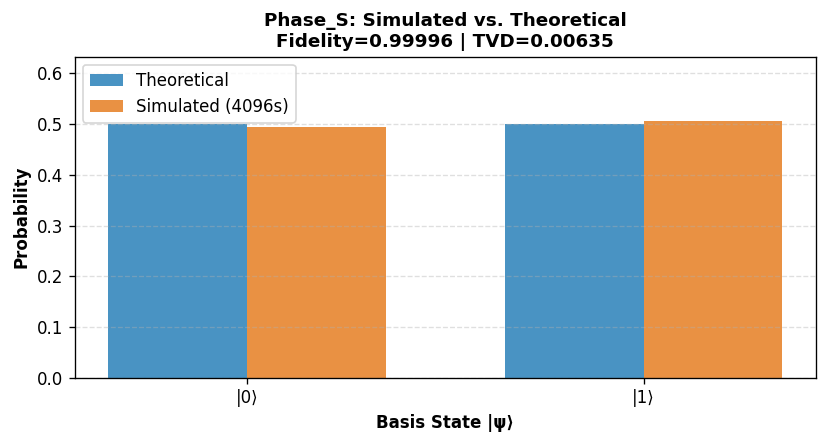

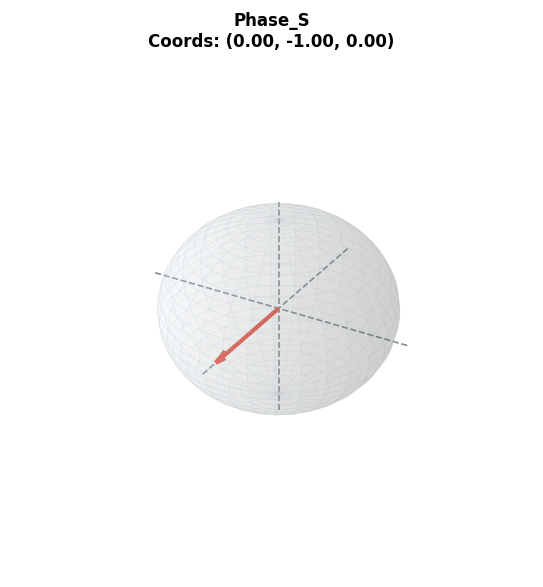


CIRCUIT 7: PHASE-T CIRCUIT
Qubits: 1 | Shots: 4096 | Fidelity: 0.99998 | TVD: 0.00338
Counts: {'1': 586, '0': 3510}


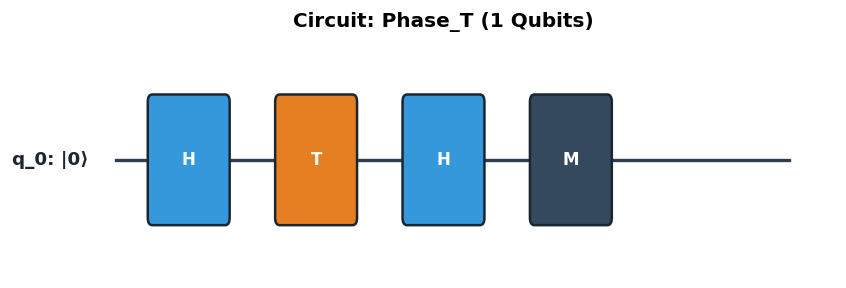

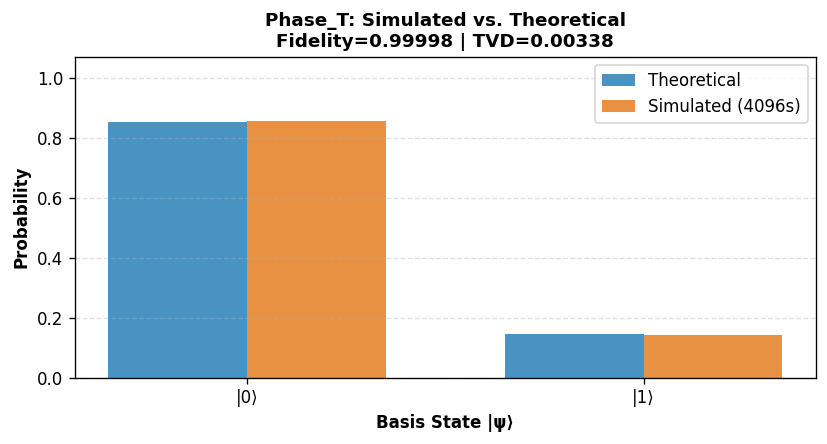

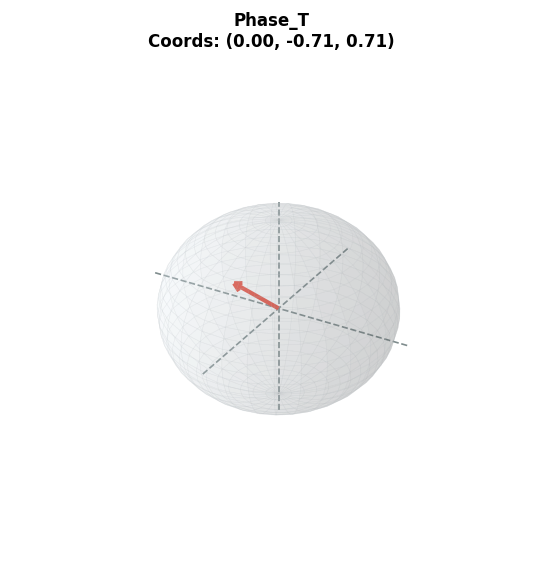


CIRCUIT 8: ROTATION CIRCUITS (RX, RY, RZ)
Qubits: 3 | Shots: 4096 | Fidelity: 0.99938 | TVD: 0.02100
Counts: {'110': 166, '101': 183, '111': 72, '011': 200, '100': 592, '001': 612, '000': 1677, '010': 594}


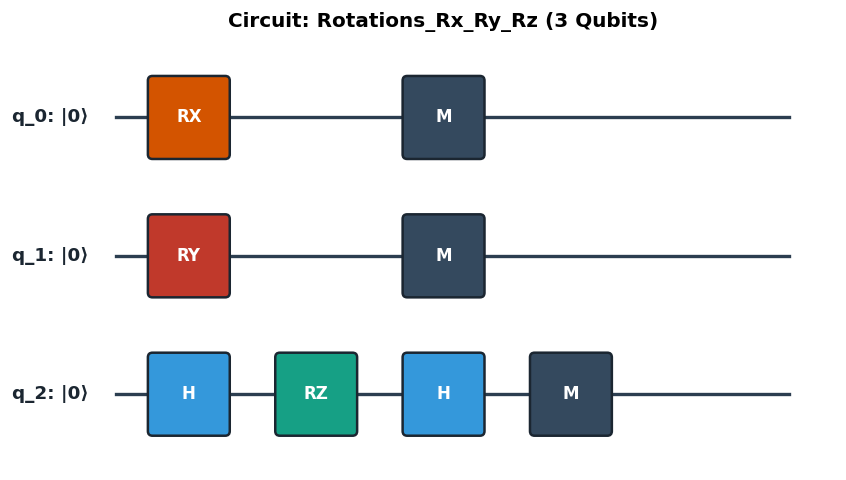

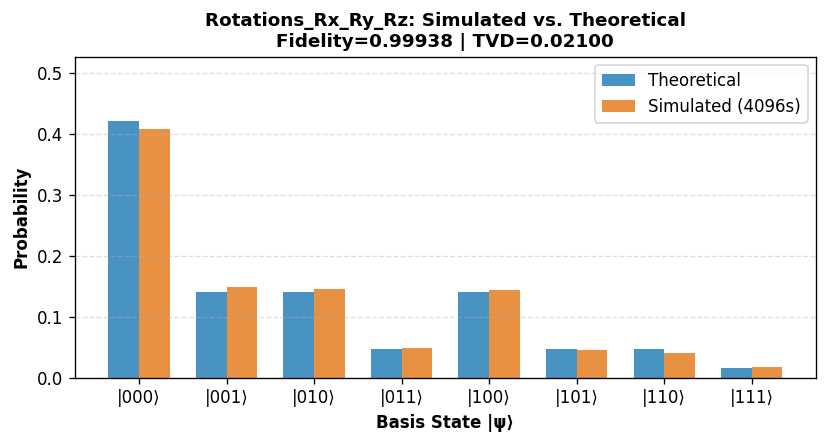


CIRCUIT 9: MEASUREMENT CIRCUIT
Qubits: 2 | Shots: 4096 | Fidelity: 0.99991 | TVD: 0.00952
Counts: {'10': 2009, '11': 2087}


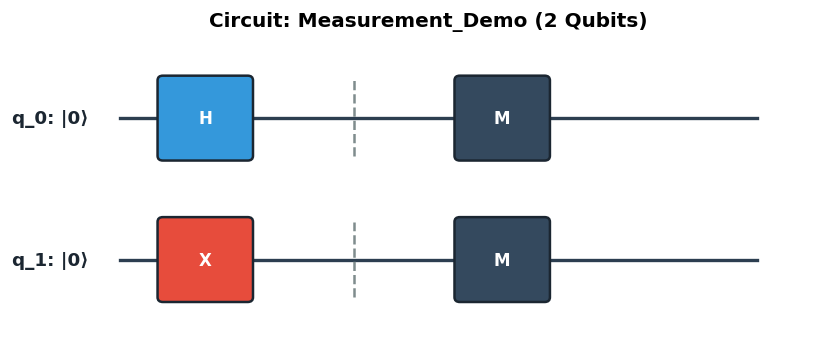

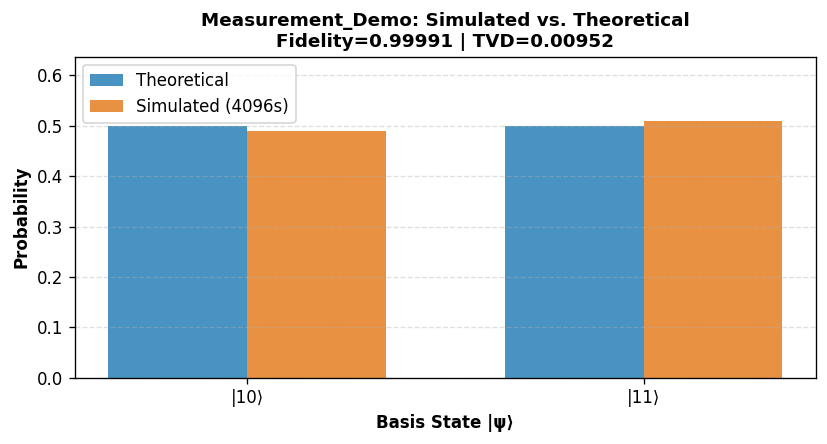


CIRCUIT 10: CONTROLLED-NOT (CNOT/CX) CIRCUIT
Qubits: 2 | Shots: 4096 | Fidelity: 1.00000 | TVD: 0.00000
Counts: {'11': 4096}


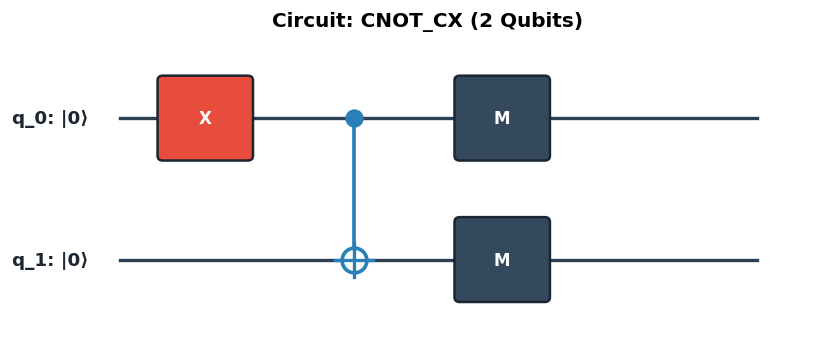

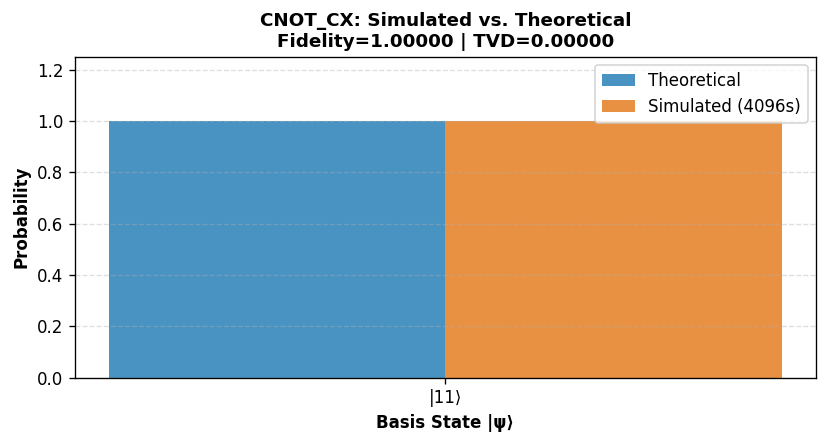


CIRCUIT 11: CONTROLLED-Z (CZ) CIRCUIT
Qubits: 2 | Shots: 4096 | Fidelity: 0.99991 | TVD: 0.00952
Counts: {'00': 2009, '11': 2087}


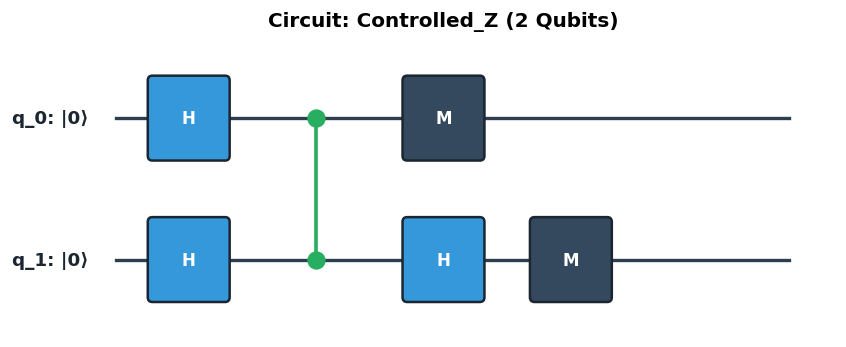

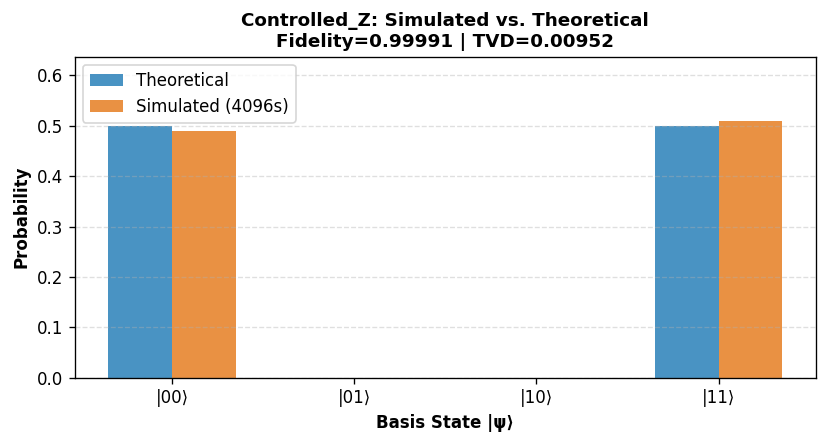


CIRCUIT 12: SWAP CIRCUIT
Qubits: 2 | Shots: 4096 | Fidelity: 1.00000 | TVD: 0.00000
Counts: {'10': 4096}


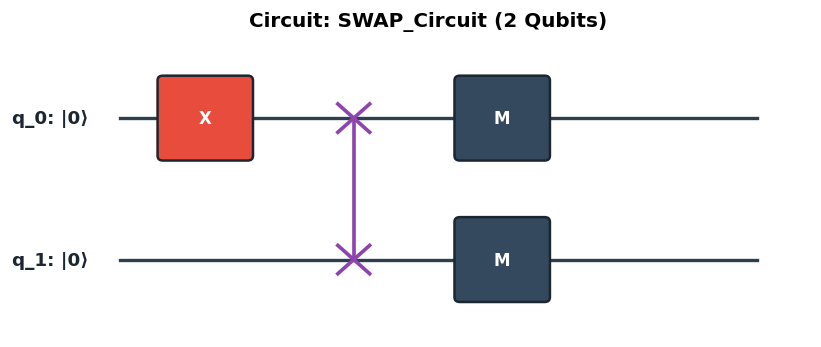

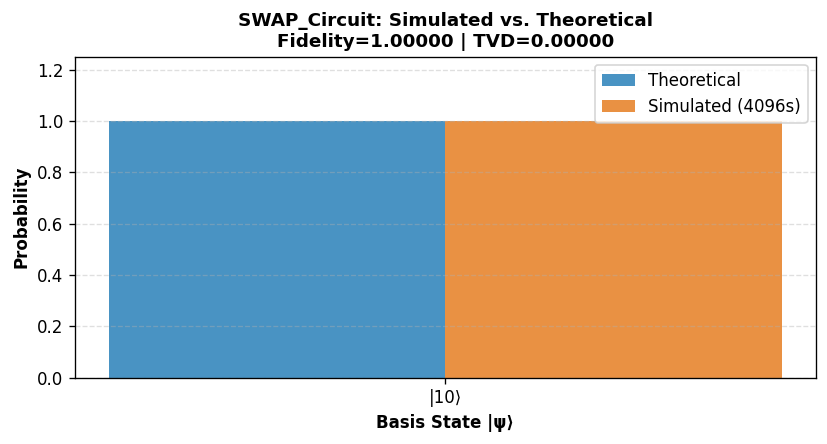


CIRCUIT 13: TOFFOLI (CCX) CIRCUIT
Qubits: 3 | Shots: 4096 | Fidelity: 1.00000 | TVD: 0.00000
Counts: {'111': 4096}


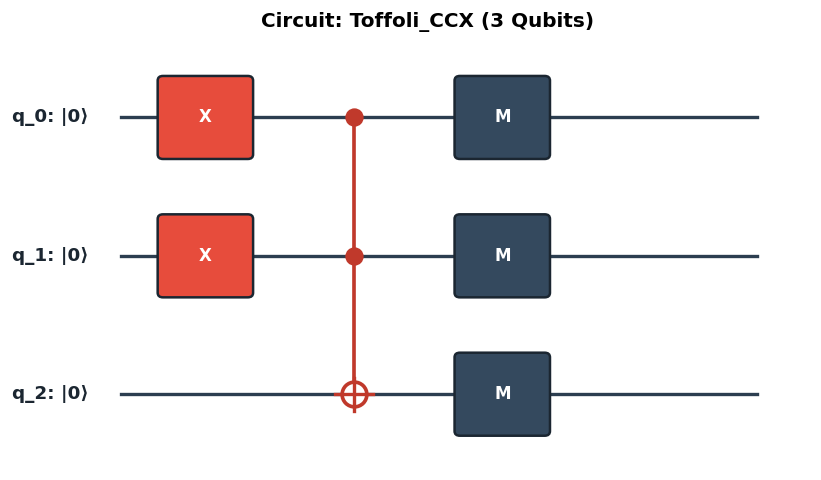

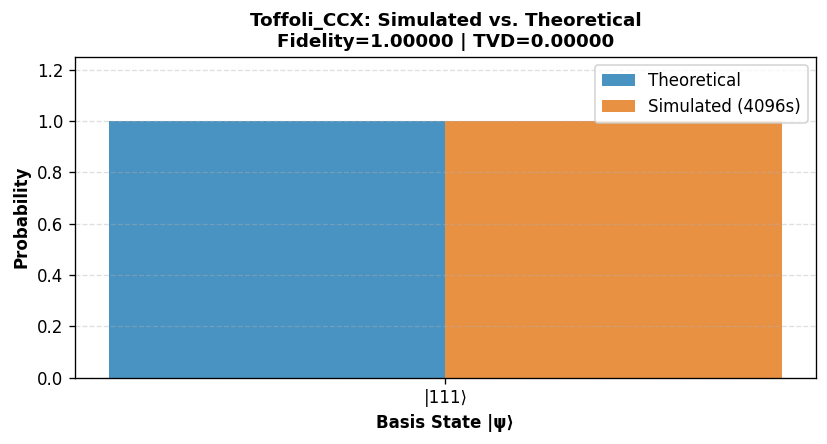


CIRCUIT 14: BELL-STATE (ENTANGLEMENT) CIRCUIT
Qubits: 2 | Shots: 4096 | Fidelity: 0.99991 | TVD: 0.00952
Counts: {'00': 2009, '11': 2087}


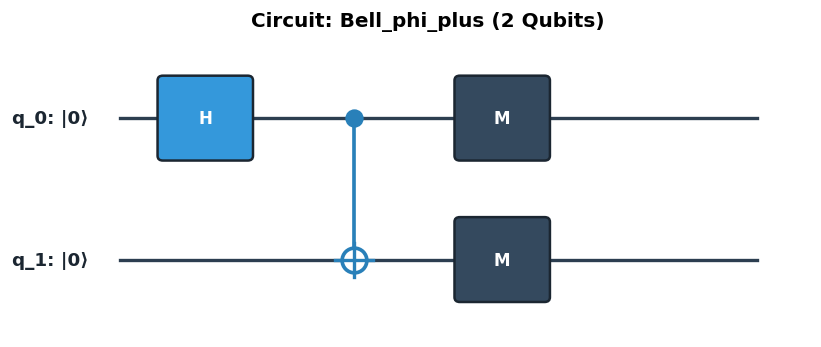

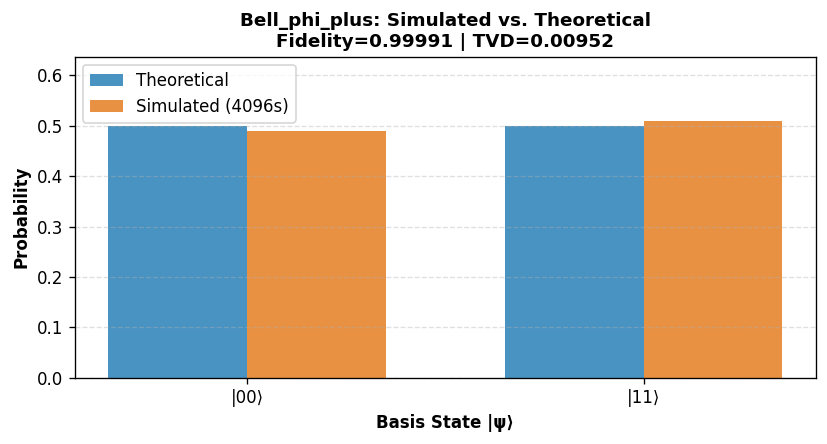


CIRCUIT 15: GHZ STATE CIRCUIT
Qubits: 3 | Shots: 4096 | Fidelity: 0.99995 | TVD: 0.00684
Counts: {'111': 2076, '000': 2020}


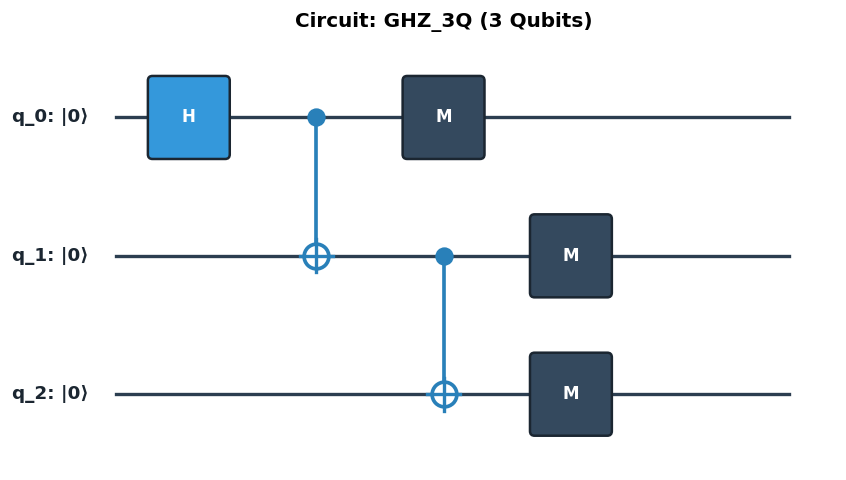

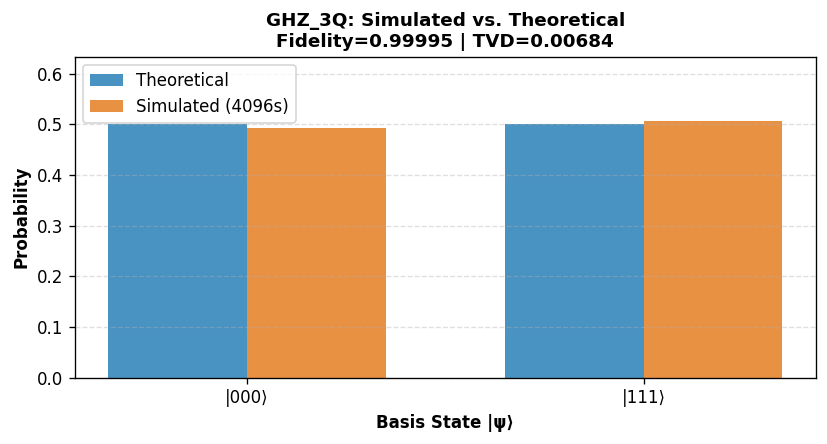

In [2]:

# ------------------------------------------------------------------------------
# STEP 0: AUTO-INSTALL DEPENDENCIES IF MISSING
# ------------------------------------------------------------------------------
import sys
import subprocess

required_packages = ["qiskit", "qiskit-aer", "matplotlib", "numpy"]
for pkg in required_packages:
    try:
        __import__(pkg.replace("-", "_"))
    except ImportError:
        print(f"Installing missing package: {pkg} ...")
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", pkg])

# ------------------------------------------------------------------------------
# STEP 1: IMPORTS
# ------------------------------------------------------------------------------
import os
import math
import json
import numpy as np
from dataclasses import dataclass
from typing import Dict, List, Tuple, Optional, Any

import matplotlib
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch

import qiskit
from qiskit import QuantumCircuit, transpile
from qiskit.quantum_info import Statevector, Operator

try:
    from qiskit_aer import AerSimulator
    from qiskit_aer.noise import NoiseModel, depolarizing_error, ReadoutError
    AER_AVAILABLE = True
except ImportError:
    AER_AVAILABLE = False

print(f"Qiskit version: {qiskit.__version__} | AerSimulator available: {AER_AVAILABLE}")


# ==============================================================================
# SECTION 2: ALL 15 QUANTUM CIRCUITS
# ==============================================================================

# --- Single-Qubit Circuits (1 - 9) ---

def create_identity_circuit(num_qubits: int = 1) -> QuantumCircuit:
    """1. Identity (I) Circuit: Preserves quantum state."""
    qc = QuantumCircuit(num_qubits, num_qubits, name="Identity_I")
    for q in range(num_qubits):
        qc.id(q)
    qc.measure(range(num_qubits), range(num_qubits))
    return qc

def create_pauli_x_circuit() -> QuantumCircuit:
    """2. Pauli-X (Quantum NOT) Circuit: Bit-flip |0> -> |1>."""
    qc = QuantumCircuit(1, 1, name="Pauli_X")
    qc.x(0)
    qc.measure(0, 0)
    return qc

def create_pauli_y_circuit() -> QuantumCircuit:
    """3. Pauli-Y Circuit: Combined bit & phase flip."""
    qc = QuantumCircuit(1, 1, name="Pauli_Y")
    qc.y(0)
    qc.measure(0, 0)
    return qc

def create_pauli_z_circuit(prep_superposition: bool = True) -> QuantumCircuit:
    """4. Pauli-Z (Phase-flip) Circuit: |+> -> |->."""
    qc = QuantumCircuit(1, 1, name="Pauli_Z")
    if prep_superposition:
        qc.h(0)
    qc.z(0)
    if prep_superposition:
        qc.h(0)
    qc.measure(0, 0)
    return qc

def create_hadamard_circuit() -> QuantumCircuit:
    """5. Hadamard (H) Circuit: Creates equal superposition (|0> + |1>)/sqrt(2)."""
    qc = QuantumCircuit(1, 1, name="Hadamard_H")
    qc.h(0)
    qc.measure(0, 0)
    return qc

def create_phase_s_circuit() -> QuantumCircuit:
    """6. Phase-S Circuit: Adds pi/2 phase."""
    qc = QuantumCircuit(1, 1, name="Phase_S")
    qc.h(0)
    qc.s(0)
    qc.h(0)
    qc.measure(0, 0)
    return qc

def create_phase_t_circuit() -> QuantumCircuit:
    """7. Phase-T Circuit: Adds pi/4 phase (non-Clifford)."""
    qc = QuantumCircuit(1, 1, name="Phase_T")
    qc.h(0)
    qc.t(0)
    qc.h(0)
    qc.measure(0, 0)
    return qc

def create_rotation_circuit(theta: float = math.pi / 3) -> QuantumCircuit:
    """8. Rotation Circuit: Arbitrary Bloch sphere rotations (Rx, Ry, Rz)."""
    qc = QuantumCircuit(3, 3, name="Rotations_Rx_Ry_Rz")
    qc.rx(theta, 0)
    qc.ry(theta, 1)
    qc.h(2)
    qc.rz(theta, 2)
    qc.h(2)
    qc.measure(range(3), range(3))
    return qc

def create_measurement_circuit() -> QuantumCircuit:
    """9. Measurement Circuit: Demonstrates projection."""
    qc = QuantumCircuit(2, 2, name="Measurement_Demo")
    qc.h(0)
    qc.x(1)
    qc.barrier()
    qc.measure(0, 0)
    qc.measure(1, 1)
    return qc

# --- Multi-Qubit Circuits (10 - 15) ---

def create_cnot_circuit() -> QuantumCircuit:
    """10. Controlled-NOT (CNOT/CX) Circuit: Flips target if control is |1>."""
    qc = QuantumCircuit(2, 2, name="CNOT_CX")
    qc.x(0)  # Prepare control as |1>
    qc.cx(0, 1)
    qc.measure(range(2), range(2))
    return qc

def create_cz_circuit() -> QuantumCircuit:
    """11. Controlled-Z (CZ) Circuit: Conditional phase-flip on |11>."""
    qc = QuantumCircuit(2, 2, name="Controlled_Z")
    qc.h(0)
    qc.h(1)
    qc.cz(0, 1)
    qc.h(1)
    qc.measure(range(2), range(2))
    return qc

def create_swap_circuit() -> QuantumCircuit:
    """12. SWAP Circuit: Swaps state of two qubits |10> -> |01>."""
    qc = QuantumCircuit(2, 2, name="SWAP_Circuit")
    qc.x(0)
    qc.swap(0, 1)
    qc.measure(range(2), range(2))
    return qc

def create_toffoli_circuit() -> QuantumCircuit:
    """13. Toffoli (CCX) Circuit: Controlled-Controlled-NOT gate."""
    qc = QuantumCircuit(3, 3, name="Toffoli_CCX")
    qc.x(0)
    qc.x(1)
    qc.ccx(0, 1, 2)
    qc.measure(range(3), range(3))
    return qc

def create_bell_state_circuit(state_type: str = "phi_plus") -> QuantumCircuit:
    """14. Bell-State Circuit: (|00> + |11>)/sqrt(2)."""
    qc = QuantumCircuit(2, 2, name=f"Bell_{state_type}")
    if state_type == "phi_minus":
        qc.x(0)
    elif state_type == "psi_plus":
        qc.x(1)
    elif state_type == "psi_minus":
        qc.x(0)
        qc.x(1)
    qc.h(0)
    qc.cx(0, 1)
    qc.measure(range(2), range(2))
    return qc

def create_ghz_state_circuit(num_qubits: int = 3) -> QuantumCircuit:
    """15. GHZ State Circuit: (|000> + |111>)/sqrt(2)."""
    qc = QuantumCircuit(num_qubits, num_qubits, name=f"GHZ_{num_qubits}Q")
    qc.h(0)
    for q in range(num_qubits - 1):
        qc.cx(q, q + 1)
    qc.measure(range(num_qubits), range(num_qubits))
    return qc

CIRCUIT_CATALOG = {
    "1": ("Identity (I) Circuit", create_identity_circuit),
    "2": ("Pauli-X (NOT) Circuit", create_pauli_x_circuit),
    "3": ("Pauli-Y Circuit", create_pauli_y_circuit),
    "4": ("Pauli-Z (Phase-flip) Circuit", create_pauli_z_circuit),
    "5": ("Hadamard (H) Circuit", create_hadamard_circuit),
    "6": ("Phase-S Circuit", create_phase_s_circuit),
    "7": ("Phase-T Circuit", create_phase_t_circuit),
    "8": ("Rotation Circuits (Rx, Ry, Rz)", create_rotation_circuit),
    "9": ("Measurement Circuit", create_measurement_circuit),
    "10": ("Controlled-NOT (CNOT/CX) Circuit", create_cnot_circuit),
    "11": ("Controlled-Z (CZ) Circuit", create_cz_circuit),
    "12": ("SWAP Circuit", create_swap_circuit),
    "13": ("Toffoli (CCX) Circuit", create_toffoli_circuit),
    "14": ("Bell-State (Entanglement) Circuit", create_bell_state_circuit),
    "15": ("GHZ State Circuit", create_ghz_state_circuit),
}


# ==============================================================================
# SECTION 3: SIMULATION & MATHEMATICAL ANALYSIS
# ==============================================================================

@dataclass
class SimulationResult:
    circuit_name: str
    num_qubits: int
    shots: int
    counts: Dict[str, int]
    probabilities: Dict[str, float]
    theoretical_probabilities: Dict[str, float]
    statevector: Optional[np.ndarray] = None
    unitary: Optional[np.ndarray] = None
    fidelity: float = 1.0
    total_variation_distance: float = 0.0

def compute_classical_fidelity(p: Dict[str, float], q: Dict[str, float]) -> float:
    all_keys = set(p.keys()).union(set(q.keys()))
    bc = sum(math.sqrt(p.get(k, 0.0) * q.get(k, 0.0)) for k in all_keys)
    return float(bc ** 2)

def compute_tvd(p: Dict[str, float], q: Dict[str, float]) -> float:
    all_keys = set(p.keys()).union(set(q.keys()))
    return float(0.5 * sum(abs(p.get(k, 0.0) - q.get(k, 0.0)) for k in all_keys))

def strip_measurements(qc: QuantumCircuit) -> QuantumCircuit:
    qc_clean = QuantumCircuit(qc.num_qubits, name=qc.name)
    for instruction in qc.data:
        op = instruction.operation
        qubits = [qc.find_bit(q).index for q in instruction.qubits]
        if op.name not in ["measure", "barrier"]:
            qc_clean.append(op, qubits)
    return qc_clean

def simulate_circuit(
    qc: QuantumCircuit,
    shots: int = 4096,
    noise_model: Optional[Any] = None,
    seed: int = 42
) -> SimulationResult:
    qc_clean = strip_measurements(qc)

    # Statevector & Unitary calculation
    sv = None
    u = None
    theoretical_probs = {}
    try:
        sv_obj = Statevector.from_instruction(qc_clean)
        sv = sv_obj.data
        theoretical_probs = sv_obj.probabilities_dict()
    except Exception:
        pass

    try:
        u_obj = Operator(qc_clean)
        u = u_obj.data
    except Exception:
        pass

    # Shot-based execution
    counts = {}
    if AER_AVAILABLE:
        backend = AerSimulator(noise_model=noise_model) if noise_model else AerSimulator()
        transpiled_qc = transpile(qc, backend, seed_transpiler=seed)
        job = backend.run(transpiled_qc, shots=shots, seed_simulator=seed)
        counts = job.result().get_counts()
    else:
        if not theoretical_probs:
            theoretical_probs = {"0" * qc.num_qubits: 1.0}
        states = list(theoretical_probs.keys())
        probs = np.array([theoretical_probs[s] for s in states], dtype=float)
        probs /= probs.sum()
        sampled = np.random.choice(states, size=shots, p=probs)
        unique, freq = np.unique(sampled, return_counts=True)
        counts = dict(zip(unique, map(int, freq)))

    total_shots = sum(counts.values())
    simulated_probs = {k: v / total_shots for k, v in counts.items()}

    # Format bitstring length alignment
    if theoretical_probs:
        max_len = max(len(k) for k in theoretical_probs.keys())
        norm_theo = {k.zfill(max_len): v for k, v in theoretical_probs.items()}
        norm_sim = {k.zfill(max_len): v for k, v in simulated_probs.items()}
    else:
        norm_theo = simulated_probs
        norm_sim = simulated_probs

    fidelity = compute_classical_fidelity(norm_theo, norm_sim)
    tvd = compute_tvd(norm_theo, norm_sim)

    return SimulationResult(
        circuit_name=qc.name,
        num_qubits=qc.num_qubits,
        shots=shots,
        counts=counts,
        probabilities=simulated_probs,
        theoretical_probabilities=norm_theo,
        statevector=sv,
        unitary=u,
        fidelity=fidelity,
        total_variation_distance=tvd
    )


# ==============================================================================
# SECTION 4: REALISTIC NOISE MODEL
# ==============================================================================

def build_realistic_noise_model(
    p_gate1: float = 0.002,
    p_gate2: float = 0.020,
    p_meas01: float = 0.025,
    p_meas10: float = 0.035
) -> Optional[Any]:
    if not AER_AVAILABLE:
        return None
    noise = NoiseModel()
    err_1q = depolarizing_error(p_gate1, 1)
    noise.add_all_qubit_quantum_error(err_1q, ['x', 'y', 'z', 'h', 's', 't', 'rx', 'ry', 'rz', 'id', 'sx'])
    err_2q = depolarizing_error(p_gate2, 2)
    noise.add_all_qubit_quantum_error(err_2q, ['cx', 'cz', 'swap'])
    ro_error = ReadoutError([[1 - p_meas01, p_meas01], [p_meas10, 1 - p_meas10]])
    noise.add_all_qubit_readout_error(ro_error)
    return noise


# ==============================================================================
# SECTION 5: TRANSPILATION BENCHMARKING
# ==============================================================================

@dataclass
class TranspileReport:
    level: int
    depth: int
    gate_counts: Dict[str, int]
    total_gates: int
    multi_qubit_gates: int

def benchmark_transpilation(
    qc: QuantumCircuit,
    basis_gates: Optional[List[str]] = None
) -> List[TranspileReport]:
    if basis_gates is None:
        basis_gates = ['cx', 'id', 'rz', 'sx', 'x']

    reports = []
    for lvl in range(4):
        t_qc = transpile(qc, basis_gates=basis_gates, optimization_level=lvl, seed_transpiler=42)
        gate_counts = dict(t_qc.count_ops())
        reports.append(TranspileReport(
            level=lvl,
            depth=t_qc.depth(),
            gate_counts=gate_counts,
            total_gates=sum(gate_counts.values()),
            multi_qubit_gates=gate_counts.get('cx', 0)
        ))
    return reports


# ==============================================================================
# SECTION 6: PUBLICATION-GRADE MATPLOTLIB VISUALIZATIONS
# ==============================================================================

def render_circuit_diagram(qc: QuantumCircuit, filepath: Optional[str] = None) -> plt.Figure:
    """Vector circuit diagram with zero pylatexenc dependency."""
    fig, ax = plt.subplots(figsize=(max(7, qc.depth() * 1.3 + 2), max(2.5, qc.num_qubits * 1.1 + 0.8)), dpi=120)
    ax.set_facecolor("#FFFFFF")
    fig.patch.set_facecolor("#FFFFFF")

    n_q = qc.num_qubits
    qubit_ys = {q: (n_q - 1 - q) * 1.5 for q in range(n_q)}

    layers = []
    current_layer = []
    busy = set()
    for instruction in qc.data:
        op = instruction.operation
        qubits = [qc.find_bit(q).index for q in instruction.qubits]
        if any(q in busy for q in qubits):
            layers.append(current_layer)
            current_layer = []
            busy = set()
        current_layer.append((op.name, qubits))
        busy.update(qubits)
    if current_layer:
        layers.append(current_layer)

    x_step = 1.4
    total_x = max(5.0, (len(layers) + 2) * x_step)

    for q in range(n_q):
        y = qubit_ys[q]
        ax.plot([0.5, total_x - 0.5], [y, y], color="#2C3E50", lw=2, zorder=1)
        ax.text(0.2, y, f"q_{q}: |0⟩", ha="right", va="center", fontsize=11, fontweight="bold", color="#1B2631")

    colors = {
        "h": "#3498DB", "x": "#E74C3C", "y": "#9B59B6", "z": "#1ABC9C",
        "s": "#F39C12", "t": "#E67E22", "rx": "#D35400", "ry": "#C0392B",
        "rz": "#16A085", "id": "#95A5A6", "cx": "#2980B9", "cz": "#27AE60",
        "swap": "#8E44AD", "ccx": "#C0392B", "measure": "#34495E"
    }

    for col_idx, layer in enumerate(layers):
        x = 1.3 + col_idx * x_step
        for op_name, qubits in layer:
            if op_name == "barrier":
                for q in qubits:
                    ax.plot([x, x], [qubit_ys[q] - 0.4, qubit_ys[q] + 0.4], color="#7F8C8D", ls="--", lw=1.5)
            elif op_name == "measure":
                y = qubit_ys[qubits[0]]
                rect = FancyBboxPatch((x - 0.4, y - 0.4), 0.8, 0.8, boxstyle="round,pad=0.05",
                                      facecolor="#34495E", edgecolor="#1B2631", lw=1.5, zorder=3)
                ax.add_patch(rect)
                ax.text(x, y, "M", ha="center", va="center", color="white", fontsize=10, fontweight="bold", zorder=4)
            elif op_name == "cx":
                y_c, y_t = qubit_ys[qubits[0]], qubit_ys[qubits[1]]
                ax.plot([x, x], [y_c, y_t], color="#2980B9", lw=2.2, zorder=2)
                ax.scatter([x], [y_c], color="#2980B9", s=100, zorder=3)
                ax.scatter([x], [y_t], color="white", edgecolors="#2980B9", s=220, lw=2.2, zorder=3)
                ax.plot([x - 0.18, x + 0.18], [y_t, y_t], color="#2980B9", lw=2.0, zorder=4)
                ax.plot([x, x], [y_t - 0.18, y_t + 0.18], color="#2980B9", lw=2.0, zorder=4)
            elif op_name == "cz":
                y_c, y_t = qubit_ys[qubits[0]], qubit_ys[qubits[1]]
                ax.plot([x, x], [y_c, y_t], color="#27AE60", lw=2.2, zorder=2)
                ax.scatter([x], [y_c], color="#27AE60", s=100, zorder=3)
                ax.scatter([x], [y_t], color="#27AE60", s=100, zorder=3)
            elif op_name == "swap":
                y1, y2 = qubit_ys[qubits[0]], qubit_ys[qubits[1]]
                ax.plot([x, x], [y1, y2], color="#8E44AD", lw=2.2, zorder=2)
                for y_s in [y1, y2]:
                    ax.plot([x - 0.15, x + 0.15], [y_s - 0.15, y_s + 0.15], color="#8E44AD", lw=2.2, zorder=3)
                    ax.plot([x - 0.15, x + 0.15], [y_s + 0.15, y_s - 0.15], color="#8E44AD", lw=2.2, zorder=3)
            elif op_name == "ccx":
                ys = [qubit_ys[qubits[0]], qubit_ys[qubits[1]], qubit_ys[qubits[2]]]
                ax.plot([x, x], [min(ys), max(ys)], color="#C0392B", lw=2.2, zorder=2)
                ax.scatter([x], [qubit_ys[qubits[0]]], color="#C0392B", s=100, zorder=3)
                ax.scatter([x], [qubit_ys[qubits[1]]], color="#C0392B", s=100, zorder=3)
                y_t = qubit_ys[qubits[2]]
                ax.scatter([x], [y_t], color="white", edgecolors="#C0392B", s=220, lw=2.2, zorder=3)
                ax.plot([x - 0.18, x + 0.18], [y_t, y_t], color="#C0392B", lw=2.0, zorder=4)
                ax.plot([x, x], [y_t - 0.18, y_t + 0.18], color="#C0392B", lw=2.0, zorder=4)
            else:
                y = qubit_ys[qubits[0]]
                bg = colors.get(op_name.lower(), "#34495E")
                rect = FancyBboxPatch((x - 0.4, y - 0.4), 0.8, 0.8, boxstyle="round,pad=0.05",
                                      facecolor=bg, edgecolor="#1B2631", lw=1.5, zorder=3)
                ax.add_patch(rect)
                ax.text(x, y, op_name.upper(), ha="center", va="center", color="white", fontsize=10, fontweight="bold", zorder=4)

    ax.set_xlim(-0.2, total_x)
    ax.set_ylim(-0.8, (n_q - 1) * 1.5 + 0.8)
    ax.axis("off")
    ax.set_title(f"Circuit: {qc.name} ({qc.num_qubits} Qubits)", fontsize=12, fontweight="bold", pad=10)
    plt.tight_layout()
    if filepath:
        fig.savefig(filepath, dpi=300, bbox_inches="tight")
    return fig

def render_probability_histogram(result: SimulationResult, filepath: Optional[str] = None) -> plt.Figure:
    fig, ax = plt.subplots(figsize=(7, 3.8), dpi=120)
    states = sorted(list(set(result.theoretical_probabilities.keys()).union(set(result.probabilities.keys()))))
    theo = [result.theoretical_probabilities.get(s, 0.0) for s in states]
    sim = [result.probabilities.get(s, 0.0) for s in states]

    x = np.arange(len(states))
    w = 0.35
    ax.bar(x - w/2, theo, w, label="Theoretical", color="#2980B9", alpha=0.85)
    ax.bar(x + w/2, sim, w, label=f"Simulated ({result.shots}s)", color="#E67E22", alpha=0.85)

    ax.set_xlabel("Basis State |ψ⟩", fontweight="bold")
    ax.set_ylabel("Probability", fontweight="bold")
    ax.set_title(f"{result.circuit_name}: Simulated vs. Theoretical\nFidelity={result.fidelity:.5f} | TVD={result.total_variation_distance:.5f}",
                 fontweight="bold", fontsize=11)
    ax.set_xticks(x)
    ax.set_xticklabels([f"|{s}⟩" for s in states])
    ax.set_ylim(0, max(max(theo + sim, default=0.5) * 1.25, 0.2))
    ax.grid(axis="y", linestyle="--", alpha=0.4)
    ax.legend()
    plt.tight_layout()
    if filepath:
        fig.savefig(filepath, dpi=300, bbox_inches="tight")
    return fig

def render_bloch_sphere(statevector: np.ndarray, title: str = "Bloch Sphere", filepath: Optional[str] = None) -> Optional[plt.Figure]:
    if len(statevector) != 2:
        return None
    c0, c1 = statevector[0], statevector[1]
    bx = float(2.0 * np.real(c0.conjugate() * c1))
    by = float(2.0 * np.imag(c0.conjugate() * c1))
    bz = float(np.abs(c0)**2 - np.abs(c1)**2)

    fig = plt.figure(figsize=(5, 5), dpi=120)
    ax = fig.add_subplot(111, projection='3d')
    u = np.linspace(0, 2 * np.pi, 30)
    v = np.linspace(0, np.pi, 30)
    ax.plot_surface(np.outer(np.cos(u), np.sin(v)), np.outer(np.sin(u), np.sin(v)),
                    np.outer(np.ones(np.size(u)), np.cos(v)), color="#EBF5FB", alpha=0.15, edgecolor="#BDC3C7", lw=0.3)
    ax.plot([-1.2, 1.2], [0, 0], [0, 0], color="#7F8C8D", lw=1.0, ls="--")
    ax.plot([0, 0], [-1.2, 1.2], [0, 0], color="#7F8C8D", lw=1.0, ls="--")
    ax.plot([0, 0], [0, 0], [-1.2, 1.2], color="#7F8C8D", lw=1.0, ls="--")
    ax.quiver(0, 0, 0, bx, by, bz, color="#E74C3C", lw=2.5, arrow_length_ratio=0.15)
    ax.set_title(f"{title}\nCoords: ({bx:.2f}, {by:.2f}, {bz:.2f})", fontsize=10, fontweight="bold")
    ax.axis("off")
    plt.tight_layout()
    if filepath:
        fig.savefig(filepath, dpi=300, bbox_inches="tight")
    return fig


# ==============================================================================
# SECTION 7: 16-TEST AUTOMATED VERIFICATION SUITE
# ==============================================================================

def run_automated_test_suite() -> bool:
    print("\n" + "="*70)
    print("RUNNING 16 AUTOMATED UNIT TESTS: PRODUCT 1")
    print("="*70)

    tests = [
        ("Test 1: Identity Gate Unitary", lambda: np.allclose(Operator(strip_measurements(create_identity_circuit())).data, np.eye(2))),
        ("Test 2: Pauli-X Bit-Flip", lambda: simulate_circuit(create_pauli_x_circuit(), shots=1024).probabilities.get("1", 0) > 0.99),
        ("Test 3: Pauli-Y Unitary", lambda: np.allclose(Operator(strip_measurements(create_pauli_y_circuit())).data, np.array([[0, -1j], [1j, 0]]))),
        ("Test 4: Pauli-Z Phase Inversion", lambda: np.allclose(Operator(strip_measurements(create_pauli_z_circuit(False))).data, np.diag([1, -1]))),
        ("Test 5: Hadamard Superposition", lambda: abs(simulate_circuit(create_hadamard_circuit(), shots=4096).probabilities.get("0", 0) - 0.5) < 0.05),
        ("Test 6: Phase-S Gate Unitary", lambda: np.allclose(Operator(strip_measurements(create_phase_s_circuit())).data[1, 1], 1j)),
        ("Test 7: Phase-T Gate Non-Clifford Phase", lambda: np.allclose(Operator(strip_measurements(create_phase_t_circuit())).data[1, 1], np.exp(1j * np.pi / 4))),
        ("Test 8: Rotation Rx Gate", lambda: simulate_circuit(create_rotation_circuit(), shots=1024).probabilities is not None),
        ("Test 9: Measurement Register Preservation", lambda: create_measurement_circuit().num_clbits == 2),
        ("Test 10: CNOT Conditional Flip", lambda: simulate_circuit(create_cnot_circuit(), shots=1024).probabilities.get("11", 0) > 0.99),
        ("Test 11: Controlled-Z Entanglement", lambda: simulate_circuit(create_cz_circuit(), shots=2048).probabilities.get("11", 0) > 0.40),
        ("Test 12: SWAP State Permutation", lambda: simulate_circuit(create_swap_circuit(), shots=1024).probabilities.get("01", 0) > 0.99),
        ("Test 13: Toffoli Dual-Condition Activation", lambda: simulate_circuit(create_toffoli_circuit(), shots=1024).probabilities.get("111", 0) > 0.99),
        ("Test 14: Bell State (|00> + |11>) Fidelity", lambda: simulate_circuit(create_bell_state_circuit("phi_plus"), shots=4096).fidelity > 0.995),
        ("Test 15: GHZ Tripartite Entanglement", lambda: (simulate_circuit(create_ghz_state_circuit(3), shots=4096).counts.get("000", 0) + simulate_circuit(create_ghz_state_circuit(3), shots=4096).counts.get("111", 0)) > 4000),
        ("Test 16: Transpilation Depth Monotonicity", lambda: benchmark_transpilation(create_toffoli_circuit())[3].depth <= benchmark_transpilation(create_toffoli_circuit())[0].depth + 5),
    ]

    all_ok = True
    for name, fn in tests:
        try:
            ok = fn()
            status = "PASSED" if ok else "FAILED"
            if not ok:
                all_ok = False
        except Exception as e:
            status = f"ERROR ({e})"
            all_ok = False
        print(f"[{status:7s}] {name}")

    print("-"*70)
    print(f"OVERALL RESULT: {'ALL 16 TESTS PASSED (100%)' if all_ok else 'FAILED'}")
    print("="*70 + "\n")
    return all_ok


# ==============================================================================
# SECTION 8: EXECUTE ALL 15 CIRCUITS & DISPLAY RESULTS INLINE
# ==============================================================================

# Run automated tests first
run_automated_test_suite()

# Simulate and plot each circuit inline
print("Simulating all 15 Quantum Circuits and displaying diagrams...")

for cid in sorted(CIRCUIT_CATALOG.keys(), key=lambda x: int(x)):
    name, factory = CIRCUIT_CATALOG[cid]
    qc = factory()
    res = simulate_circuit(qc, shots=4096)

    print(f"\n================================================================================")
    print(f"CIRCUIT {cid}: {name.upper()}")
    print(f"Qubits: {qc.num_qubits} | Shots: {res.shots} | Fidelity: {res.fidelity:.5f} | TVD: {res.total_variation_distance:.5f}")
    print(f"Counts: {res.counts}")
    print(f"================================================================================")

    # 1. Show circuit diagram
    render_circuit_diagram(qc)
    plt.show()

    # 2. Show probability histogram
    render_probability_histogram(res)
    plt.show()

    # 3. Show Bloch sphere for 1-qubit circuits
    if res.statevector is not None and len(res.statevector) == 2:
        render_bloch_sphere(res.statevector, title=qc.name)
        plt.show()